<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas
import pandas as pd
import matplotlib.pyplot as plt

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [2]:
#Importation du fichier population.csv
population = pd.read_csv('population.csv')

#Importation du fichier dispo_alimentaire.csv
dispo = pd.read_csv('dispo_alimentaire.csv')

#Importation du fichier aide_alimentaire.csv
aide = pd.read_csv('aide_alimentaire.csv')

#Importation du fichier sous_nutrition.csv
faim = pd.read_csv('sous_nutrition.csv')

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [3]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [4]:
#Consulter le nombre de colonnes
print ("nombre de colonnes : {}".format(population.shape[1])) 

#La nature des données dans chacune des colonnes
print (population.dtypes)

#Le nombre de valeurs présentes dans chacune des colonnes
print (population.count())

nombre de colonnes : 3
Zone       object
Année       int64
Valeur    float64
dtype: object
Zone      1416
Année     1416
Valeur    1416
dtype: int64


In [5]:
#Affichage les 5 premières lignes de la table
print (population.head())

          Zone  Année     Valeur
0  Afghanistan   2013  32269.589
1  Afghanistan   2014  33370.794
2  Afghanistan   2015  34413.603
3  Afghanistan   2016  35383.032
4  Afghanistan   2017  36296.113


In [6]:
#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000
population['Valeur'] = population['Valeur'] * 1000

In [7]:
#changement du nom de la colonne Valeur par Population
population = population.rename(columns = {'Valeur' : 'population'})

In [8]:
#Affichage les 5 premières lignes de la table pour voir les modifications
print (population.head())

          Zone  Année  population
0  Afghanistan   2013  32269589.0
1  Afghanistan   2014  33370794.0
2  Afghanistan   2015  34413603.0
3  Afghanistan   2016  35383032.0
4  Afghanistan   2017  36296113.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [9]:
#Afficher les dimensions du dataset
print (dispo.shape)
print ("nombre de lignes : {}".format(dispo.shape[0]))

(15605, 18)
nombre de lignes : 15605


In [10]:
#Consulter le nombre de colonnes
print ("nombre de colonnes : {}".format(dispo.shape[1])) 

nombre de colonnes : 18


In [11]:
#Affichage les 5 premières lignes de la table
print (dispo.head())

          Zone                Produit   Origine  Aliments pour animaux  \
0  Afghanistan       Abats Comestible   animale                    NaN   
1  Afghanistan        Agrumes, Autres  vegetale                    NaN   
2  Afghanistan  Aliments pour enfants  vegetale                    NaN   
3  Afghanistan                 Ananas  vegetale                    NaN   
4  Afghanistan                Bananes  vegetale                    NaN   

   Autres Utilisations  Disponibilité alimentaire (Kcal/personne/jour)  \
0                  NaN                                             5.0   
1                  NaN                                             1.0   
2                  NaN                                             1.0   
3                  NaN                                             0.0   
4                  NaN                                             4.0   

   Disponibilité alimentaire en quantité (kg/personne/an)  \
0                                               1

In [12]:
#remplacement des NaN dans le dataset par des 0
dispo = dispo.fillna(0)

In [13]:
#multiplication de toutes les lignes contenant des milliers de tonnes en Kg
dispo['Aliments pour animaux'] = dispo['Aliments pour animaux'] * 1000000
dispo['Autres Utilisations'] = dispo['Autres Utilisations'] * 1000000
dispo['Disponibilité intérieure'] = dispo['Disponibilité intérieure'] * 1000000
dispo['Exportations - Quantité'] = dispo['Exportations - Quantité'] * 1000000
dispo['Importations - Quantité'] = dispo['Importations - Quantité'] * 1000000
dispo['Nourriture'] = dispo['Nourriture'] * 1000000
dispo['Pertes'] = dispo['Pertes'] * 1000000
dispo['Production'] = dispo['Production'] * 1000000
dispo['Semences'] = dispo['Semences'] * 1000000
dispo['Traitement'] = dispo['Traitement'] * 1000000
dispo['Variation de stock'] = dispo['Variation de stock'] * 1000000

In [14]:
#Affichage les 5 premières lignes de la table
print (dispo.head())

          Zone                Produit   Origine  Aliments pour animaux  \
0  Afghanistan       Abats Comestible   animale                    0.0   
1  Afghanistan        Agrumes, Autres  vegetale                    0.0   
2  Afghanistan  Aliments pour enfants  vegetale                    0.0   
3  Afghanistan                 Ananas  vegetale                    0.0   
4  Afghanistan                Bananes  vegetale                    0.0   

   Autres Utilisations  Disponibilité alimentaire (Kcal/personne/jour)  \
0                  0.0                                             5.0   
1                  0.0                                             1.0   
2                  0.0                                             1.0   
3                  0.0                                             0.0   
4                  0.0                                             4.0   

   Disponibilité alimentaire en quantité (kg/personne/an)  \
0                                               1

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [15]:
#Afficher les dimensions du dataset
print (aide.shape)

(1475, 4)


In [16]:
#Consulter le nombre de colonnes
print ("nombre de colonnes : {}".format(aide.shape[1])) 

nombre de colonnes : 4


In [17]:
#Affichage les 5 premières lignes de la table
print (aide.head())

  Pays bénéficiaire  Année              Produit  Valeur
0       Afghanistan   2013  Autres non-céréales     682
1       Afghanistan   2014  Autres non-céréales     335
2       Afghanistan   2013         Blé et Farin   39224
3       Afghanistan   2014         Blé et Farin   15160
4       Afghanistan   2013             Céréales   40504


In [18]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide = aide.rename(columns = {'Pays bénéficiaire' : 'Zone'})

In [19]:
#Multiplication de la colonne Aide_alimentaire qui contient des tonnes par 1000 pour avoir des kg
aide['Valeur'] = aide['Valeur'] * 1000

In [20]:
#Affichage les 5 premières lignes de la table
print (aide.head())

          Zone  Année              Produit    Valeur
0  Afghanistan   2013  Autres non-céréales    682000
1  Afghanistan   2014  Autres non-céréales    335000
2  Afghanistan   2013         Blé et Farin  39224000
3  Afghanistan   2014         Blé et Farin  15160000
4  Afghanistan   2013             Céréales  40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [21]:
#Afficher les dimensions du dataset
print (faim.shape)

(1218, 3)


In [22]:
#Consulter le nombre de colonnes
print ("nombre de colonnes : {}".format(faim.shape[1]))  

nombre de colonnes : 3


In [23]:
#Afficher les 5 premières lignes de la table
print (faim.head())

          Zone      Année Valeur
0  Afghanistan  2012-2014    8.6
1  Afghanistan  2013-2015    8.8
2  Afghanistan  2014-2016    8.9
3  Afghanistan  2015-2017    9.7
4  Afghanistan  2016-2018   10.5


In [24]:
#Conversion de la colonne sous nutrition en numérique
faim['Valeur'] = pd.to_numeric(faim['Valeur'], errors='coerce')

In [25]:
#Conversion de la colonne (avec l'argument errors=coerce qui permet de convertir automatiquement les lignes qui ne sont pas des nombres en NaN)
#Puis remplacement des NaN en 0
faim = faim.fillna(0)

In [26]:
#changement du nom de la colonne Valeur par sous_nutrition
faim = faim.rename(columns = {'Valeur' : 'sous_nutrition'})

In [27]:
#Multiplication de la colonne sous_nutrition par 1000000
faim['sous_nutrition'] = faim['sous_nutrition'] * 1000000

In [28]:
#Afficher les 5 premières lignes de la table
print(faim.head())

          Zone      Année  sous_nutrition
0  Afghanistan  2012-2014       8600000.0
1  Afghanistan  2013-2015       8800000.0
2  Afghanistan  2014-2016       8900000.0
3  Afghanistan  2015-2017       9700000.0
4  Afghanistan  2016-2018      10500000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [29]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017
faim2017 = faim[faim['Année'] == '2016-2018']
pop2017 = population[population['Année'] == 2017]
pop_nut = pd.merge(pop2017 , faim2017, on='Zone', how='inner', suffixes=('_population', '_faim'))

In [30]:
#Affichage du dataset
print(pop_nut.head())

             Zone  Année_population  population Année_faim  sous_nutrition
0     Afghanistan              2017  36296113.0  2016-2018      10500000.0
1  Afrique du Sud              2017  57009756.0  2016-2018       3100000.0
2         Albanie              2017   2884169.0  2016-2018        100000.0
3         Algérie              2017  41389189.0  2016-2018       1300000.0
4       Allemagne              2017  82658409.0  2016-2018             0.0


In [31]:
#Calcul et affichage du nombre de personnes en état de sous nutrition
total_sous_nutrition = pop_nut['sous_nutrition'].sum()
print("Nombre total de personnes en sous-nutrition en 2017 :", total_sous_nutrition)

Nombre total de personnes en sous-nutrition en 2017 : 535700000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personne qui pourrait être nourries</h3>
</div>

In [32]:
#Combien mange en moyenne un être humain ? Source => 
# 2200

In [33]:
#On commence par faire une jointure entre le data frame population et Dispo_alimentaire afin d'ajouter dans ce dernier la population
dispo = pd.merge(dispo, pop2017, on='Zone')

In [34]:
#Affichage du nouveau dataframe
print(dispo.head()) 

          Zone                Produit   Origine  Aliments pour animaux  \
0  Afghanistan       Abats Comestible   animale                    0.0   
1  Afghanistan        Agrumes, Autres  vegetale                    0.0   
2  Afghanistan  Aliments pour enfants  vegetale                    0.0   
3  Afghanistan                 Ananas  vegetale                    0.0   
4  Afghanistan                Bananes  vegetale                    0.0   

   Autres Utilisations  Disponibilité alimentaire (Kcal/personne/jour)  \
0                  0.0                                             5.0   
1                  0.0                                             1.0   
2                  0.0                                             1.0   
3                  0.0                                             0.0   
4                  0.0                                             4.0   

   Disponibilité alimentaire en quantité (kg/personne/an)  \
0                                               1

In [35]:
#Création de la colonne dispo_kcal avec calcul des kcal disponibles mondialement
dispo['dispo_kcal'] = dispo['Disponibilité alimentaire (Kcal/personne/jour)'] * dispo['population']
total_kcal = dispo['dispo_kcal'].sum()
print("Quantité total de kcal disponible mondialement par jour :", total_kcal )

Quantité total de kcal disponible mondialement par jour : 20918984627331.0


In [36]:
#Calcul du nombre d'humains pouvant être nourris
nb_humain = total_kcal / 2200
print("Nombre d'humains pouvant être nourris :", round(nb_humain, 2))

Nombre d'humains pouvant être nourris : 9508629376.06


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personne qui pourrait être nourrie avec les produits végétaux</h3>
</div>

In [37]:
#Transfert des données avec les végétaux dans un nouveau dataframe
dispo_veg = dispo[dispo['Origine'] == 'vegetale']

In [38]:
#Calcul du nombre de kcal disponible pour les végétaux
total_kcal_veg = dispo_veg['dispo_kcal'].sum()
print("Quantité total de kcal vegetal disponible mondialement par jour :", total_kcal_veg)

Quantité total de kcal vegetal disponible mondialement par jour : 17260764211501.0


In [39]:
#Calcul du nombre d'humains pouvant être nourris avec les végétaux
nb_humain_veg = total_kcal_veg / 2200
print("Nombre d'humains pouvant être nourris avec des végétaux :", round(nb_humain_veg, 2))

Nombre d'humains pouvant être nourris avec des végétaux : 7845801914.32


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

In [40]:
#Calcul de la disponibilité totale
dispo_globale = dispo['Disponibilité intérieure'].sum()
print("Disponibilité totale mondiale :", dispo_globale, "kg")

Disponibilité totale mondiale : 9733927000000.0 kg


In [41]:
#création d'une boucle for pour afficher les différentes valeurs en fonction des colonnes aliments pour animaux, pertes, nourritures, 
colonnes_principales = ['Aliments pour animaux', 'Pertes', 'Nourriture']
for col in colonnes_principales:
    print(f"Total {col} :", dispo[col].sum())

Total Aliments pour animaux : 1288002000000.0
Total Pertes : 452283000000.0
Total Nourriture : 4805525000000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [42]:
#Création d'une liste avec toutes les variables
colonnes_utilisations = [
    'Aliments pour animaux', 'Autres Utilisations', 'Pertes',
    'Nourriture', 'Semences', 'Traitement', 'Variation de stock',
    'Exportations - Quantité', 'Importations - Quantité', 'Production'
]

In [43]:
#Création d'un dataframe avec les informations uniquement pour ces céréales
produits_cereales = ["Blé", "Maïs", "Millet", "Orge", "Riz (Eq Blanchi)", "Avoine", "Seigle", "Sorgho", "Céréales, Autres"]
cereales = dispo[dispo['Produit'].isin(produits_cereales)]

In [44]:
#Affichage de la proportion d'alimentation animale
part_animaux = cereales['Aliments pour animaux'].sum() / cereales['Disponibilité intérieure'].sum()
print("Proportion globale d’alimentation animale :", round(part_animaux * 100, 2), "%")

Proportion globale d’alimentation animale : 36.14 %


In [45]:
#Affichage de la proportion d'alimentation humaine
part_humain = cereales['Nourriture'].sum() / cereales['Disponibilité intérieure'].sum()
print("Proportion globale d’alimentation humaine :", round(part_humain * 100, 2), "%")

Proportion globale d’alimentation humaine : 42.91 %


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [46]:
#Création de la colonne proportion par pays
pop_nut['proportion'] = ((pop_nut['sous_nutrition'] / pop_nut['population'])*100).round(2)

In [47]:
#affichage après trie des 10 pires pays
pop_nut.sort_values(by='proportion', ascending=False).reset_index()
pop_nut[['Zone', 'proportion']].head(10).style.set_properties(**{'text-align': 'center'}).set_table_styles([{
        'selector': 'th',
        'props': [('text-align', 'center')]
    }])

,Zone,proportion
0,Afghanistan,28.930000
1,Afrique du Sud,5.440000
2,Albanie,3.470000
3,Algérie,3.140000
4,Allemagne,0.000000
5,Andorre,0.000000
6,Angola,19.450000
7,Antigua-et-Barbuda,0.000000
8,Arabie saoudite,4.830000
9,Argentine,3.410000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [48]:
#calcul du total de l'aide alimentaire par pays
aide_pays = aide.groupby('Zone')['Valeur'].sum().reset_index()

In [49]:
#affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
aide_pays.sort_values(by='Valeur', ascending=False, inplace=True)
print(aide_pays.head(10))

                                Zone      Valeur
50         République arabe syrienne  1858943000
75                          Éthiopie  1381294000
70                             Yémen  1206484000
61                     Soudan du Sud   695248000
60                            Soudan   669784000
30                             Kenya   552836000
3                         Bangladesh   348188000
59                           Somalie   292678000
53  République démocratique du Congo   288502000
43                             Niger   276344000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [50]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
aide_pays_annee = aide.groupby(['Zone', 'Année'])['Valeur'].sum().reset_index()
print(aide_pays_annee.head())

          Zone  Année     Valeur
0  Afghanistan   2013  128238000
1  Afghanistan   2014   57214000
2      Algérie   2013   35234000
3      Algérie   2014   18980000
4      Algérie   2015   17424000


In [51]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficiées de l'aide alimentaire
top5_pays = aide_pays['Zone'].head(5).tolist()
print(top5_pays)

['République arabe syrienne', 'Éthiopie', 'Yémen', 'Soudan du Sud', 'Soudan']


In [52]:
#On filtre sur le dataframe avec notre liste
aide_top5 = aide_pays_annee[aide_pays_annee['Zone'].isin(top5_pays)]

In [53]:
# Affichage des pays avec l'aide alimentaire par année
print(aide_top5)

                          Zone  Année     Valeur
157  République arabe syrienne   2013  563566000
158  République arabe syrienne   2014  651870000
159  République arabe syrienne   2015  524949000
160  République arabe syrienne   2016  118558000
189                     Soudan   2013  330230000
190                     Soudan   2014  321904000
191                     Soudan   2015   17650000
192              Soudan du Sud   2013  196330000
193              Soudan du Sud   2014  450610000
194              Soudan du Sud   2015   48308000
214                      Yémen   2013  264764000
215                      Yémen   2014  103840000
216                      Yémen   2015  372306000
217                      Yémen   2016  465574000
225                   Éthiopie   2013  591404000
226                   Éthiopie   2014  586624000
227                   Éthiopie   2015  203266000


In [54]:
aide_top5_pivot = aide_top5.pivot(index='Année', columns='Zone', values='Valeur')
aide_top5_pivot

Zone,République arabe syrienne,Soudan,Soudan du Sud,Yémen,Éthiopie
Année,,,,,
2013,563566000.0,330230000.0,196330000.0,264764000.0,591404000.0
2014,651870000.0,321904000.0,450610000.0,103840000.0,586624000.0
2015,524949000.0,17650000.0,48308000.0,372306000.0,203266000.0
2016,118558000.0,NaN,NaN,465574000.0,NaN


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [55]:
#Calcul de la disponibilité en kcal par personne par jour par pays
dispo_par_pays = dispo.groupby('Zone')['Disponibilité alimentaire (Kcal/personne/jour)'].sum().reset_index()

In [56]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 
dispo_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=True).head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
127,République centrafricaine,1879.0
164,Zambie,1924.0
91,Madagascar,2056.0
0,Afghanistan,2087.0
65,Haïti,2089.0
132,République populaire démocratique de Corée,2093.0
150,Tchad,2109.0
165,Zimbabwe,2113.0
114,Ouganda,2126.0
152,Timor-Leste,2129.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [57]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 
dispo_par_pays.sort_values(by='Disponibilité alimentaire (Kcal/personne/jour)', ascending=False).head(10)

,Zone,Disponibilité alimentaire (Kcal/personne/jour)
11,Autriche,3770.0
16,Belgique,3737.0
157,Turquie,3708.0
169,États-Unis d'Amérique,3682.0
74,Israël,3610.0
72,Irlande,3602.0
75,Italie,3578.0
89,Luxembourg,3540.0
166,Égypte,3518.0
4,Allemagne,3503.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [58]:
#création d'un dataframe avec uniquement la Thaïlande 
thai_dispo = dispo[dispo['Zone'] == 'Thaïlande'].reset_index()

In [59]:
#Calcul de la sous nutrition en Thaïlande
faim = faim.replace(regex={'2012-2014' : '2013' , '2013-2015' : '2014' , '2014-2016' : '2015' ,
                           '2015-2017' : '2016' , '2016-2018' : '2017' , '2017-2019' : '2018'})
thai_pop = population.loc[population['Zone'] == 'Thaïlande']
thai_faim = faim.loc[faim['Zone'] == 'Thaïlande']

In [60]:
thai_faim['Année'] = thai_faim['Année'].astype(int)
thai_pop['Année'] = thai_pop['Année'].astype(int)

C:\Users\Vecto\AppData\Local\Temp\ipykernel_1712\2820568404.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  thai_faim['Année'] = thai_faim['Année'].astype(int)
C:\Users\Vecto\AppData\Local\Temp\ipykernel_1712\2820568404.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  thai_pop['Année'] = thai_pop['Année'].astype(int)


In [61]:
thai_faim_pop = pd.merge(thai_faim, thai_pop, on='Année')

In [62]:
thai_faim_pop['proportion_faim'] = round(thai_faim_pop['sous_nutrition'] / thai_faim_pop['population']*100 , 2)

In [63]:
thai_faim_pop.head(10)

,Zone_x,Année,sous_nutrition,Zone_y,population,proportion_faim
0,Thaïlande,2013,6200000.0,Thaïlande,68144518.0,9.10
1,Thaïlande,2014,6000000.0,Thaïlande,68438746.0,8.77
2,Thaïlande,2015,5900000.0,Thaïlande,68714511.0,8.59
3,Thaïlande,2016,6000000.0,Thaïlande,68971308.0,8.70
4,Thaïlande,2017,6200000.0,Thaïlande,69209810.0,8.96
5,Thaïlande,2018,6500000.0,Thaïlande,69428453.0,9.36


In [64]:
# On calcule la proportion exportée en fonction de la proportion
thai_dispo['proportion_exportee'] = thai_dispo['Exportations - Quantité'] / thai_dispo['Production']
manioc = thai_dispo[thai_dispo["Produit"] == "Manioc"]
print(manioc[['Zone' , 'Produit' ,'Exportations - Quantité', 'Production', 'proportion_exportee' ]])

         Zone Produit  Exportations - Quantité    Production  \
50  Thaïlande  Manioc             2.521400e+10  3.022800e+10   

    proportion_exportee  
50             0.834127  


In [65]:
print(thai_dispo[['Zone' , 'Produit' ,'Exportations - Quantité', 'Production', 'proportion_exportee' ]])

         Zone                 Produit  Exportations - Quantité    Production  \
0   Thaïlande        Abats Comestible             5.000000e+06  4.500000e+07   
1   Thaïlande         Agrumes, Autres             6.000000e+06  1.200000e+07   
2   Thaïlande  Alcool, non Comestible             1.100000e+08  4.470000e+08   
3   Thaïlande   Aliments pour enfants             7.000000e+06  0.000000e+00   
4   Thaïlande                  Ananas             1.449000e+09  2.209000e+09   
..        ...                     ...                      ...           ...   
90  Thaïlande        Viande de Suides             2.200000e+07  8.910000e+08   
91  Thaïlande     Viande de Volailles             5.360000e+08  1.470000e+09   
92  Thaïlande           Viande, Autre             9.600000e+07  0.000000e+00   
93  Thaïlande                     Vin             8.000000e+06  0.000000e+00   
94  Thaïlande          Épices, Autres             4.200000e+07  1.430000e+08   

    proportion_exportee  
0            

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse complémentaires</h2>
</div>

In [66]:
#ajouter en dessous toutes les analyses complémtaires

In [67]:
# afficher le nombre des pays dans chaque fichier
print(dispo['Zone'].nunique())
print(population['Zone'].nunique())
print(faim['Zone'].nunique())
print(aide['Zone'].nunique())

172
236
203
76


In [68]:
# voir si la sous-nutrition est due à la manque de disponibilité alimentaire dans le pays
# joindre la disponibilité par pays et par année avec la population et la sous-nutrition
dispo_pop_faim = pd.merge(pop_nut , dispo_par_pays , on='Zone')

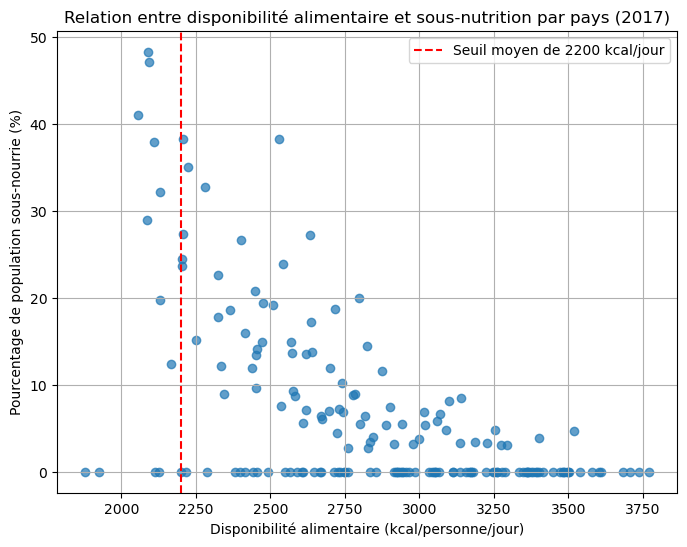

In [69]:
# graph
plt.figure(figsize=(8,6))
plt.scatter(dispo_pop_faim['Disponibilité alimentaire (Kcal/personne/jour)'], 
            dispo_pop_faim['proportion'], 
            alpha=0.7)

plt.xlabel('Disponibilité alimentaire (kcal/personne/jour)')
plt.ylabel('Pourcentage de population sous-nourrie (%)')
plt.title('Relation entre disponibilité alimentaire et sous-nutrition par pays (2017)')
# Ligne de référence autour de 2200 kcal
plt.axvline(2200, color='red', linestyle='--', label='Seuil moyen de 2200 kcal/jour')
plt.legend()
plt.grid(True)
# plt.savefig("correlation_dispo_faim.png", dpi=300, bbox_inches='tight')
# pour sauvgarder le fichier, si pas encore fait, sinon juste afficher
plt.show()